# Original experiment runs (record with outputs)

This notebook collects, **unchanged**, the Google Colab cells that produced the reported results of the paper *A Comprehensive Evaluation of Unsupervised Clustering Algorithms for Credit Card Fraud Detection in Large-Scale Transaction Datasets*, together with their original outputs.

| Section | Algorithm | Feature space | Reported in |
|---|---|---|---|
| 1 | Data loading, merge, label encoding | – | Sections 3.2–3.3 |
| 2 | KMC (K = 2), 10-fold | unscaled | Tables 7 and 9 |
| 3 | AHC (mini-batch k-means + Ward), 10-fold | unscaled | Table 7 |
| 4 | GMMC (2 components), 10-fold | standardized | Table 7 |
| 5 | FCMC (m = 2.0), 10-fold | unscaled | Table 7 |

**Notes**

* The file paths point to the authors' Google Drive. To re-run, place `cc_info.csv` and `transactions.csv.zip` in `data/` and change the two `pd.read_csv` paths, or use the scripts in `scripts/`, which reproduce the same pipeline.
* The `State` column is encoded from the `city` column (`label_encoder.fit_transform(df['city'])`). This coding error is reported in Section 3.3 of the paper and is kept here so that the outputs match the published tables.
* The cells also print WCSS and a gap statistic. These were exploratory and are **not** reported in the paper.
* AHC and GMMC were run in the Colab session of `Untitled0.ipynb`, and KMC and FCMC in the session of `test.ipynb`; both sessions used the same data-preparation cell.

## 1. Data loading, merging, and label encoding

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

cc=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/_paper/unsupervised credit card fraud/cc_info.csv')
trans=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/_paper/unsupervised credit card fraud/transactions.csv.zip')

df = pd.merge(cc, trans, on='credit_card', how='left')



from sklearn.preprocessing import LabelEncoder

# Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit and transform the 'city' column
df['City'] = label_encoder.fit_transform(df['city'])

# Display a few rows to verify the encoding
print(df[['city', 'City']].head())



from sklearn.preprocessing import LabelEncoder

# Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit and transform the 'city' column
df['State'] = label_encoder.fit_transform(df['city'])

# Display a few rows to verify the encoding
print(df[['state', 'State']].head())



df
df=df[[ 'credit_card','State','City', 'zipcode', 'credit_card_limit',
        'transaction_dollar_amount', 'Long', 'Lat']]

     city  City
0  Dallas    29
1  Dallas    29
2  Dallas    29
3  Dallas    29
4  Dallas    29
  state  State
0    PA     29
1    PA     29
2    PA     29
3    PA     29
4    PA     29


## 2. K-Means Clustering (KMC), unscaled features

Fold 1: Silhouette=0.6167, CH=748133.38, DB=0.5112, WCSS=453295023941578726114975034344734720.00, Gap=-0.0145
Fold 2: Silhouette=0.6168, CH=748076.34, DB=0.5112, WCSS=453071840976106449159724406700769280.00, Gap=-0.0141
Fold 3: Silhouette=0.6170, CH=749093.11, DB=0.5108, WCSS=452992672051728272267288892934193152.00, Gap=-0.0132
Fold 4: Silhouette=0.6167, CH=747743.38, DB=0.5114, WCSS=453368124040160293592237261300170752.00, Gap=-0.0148
Fold 5: Silhouette=0.6169, CH=748690.72, DB=0.5110, WCSS=452850007368551659276938338705080320.00, Gap=-0.0130
Fold 6: Silhouette=0.6171, CH=749183.12, DB=0.5108, WCSS=452965960204632072869715405975846912.00, Gap=-0.0127
Fold 7: Silhouette=0.6167, CH=747663.78, DB=0.5114, WCSS=453161717228351371503435702935224320.00, Gap=-0.0135
Fold 8: Silhouette=0.6165, CH=747235.64, DB=0.5115, WCSS=453419321531020460759636491341135872.00, Gap=-0.0139
Fold 9: Silhouette=0.6168, CH=748195.00, DB=0.5112, WCSS=453136184498334295180548208978821120.00, Gap=-0.0132
Fold 10: S

/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


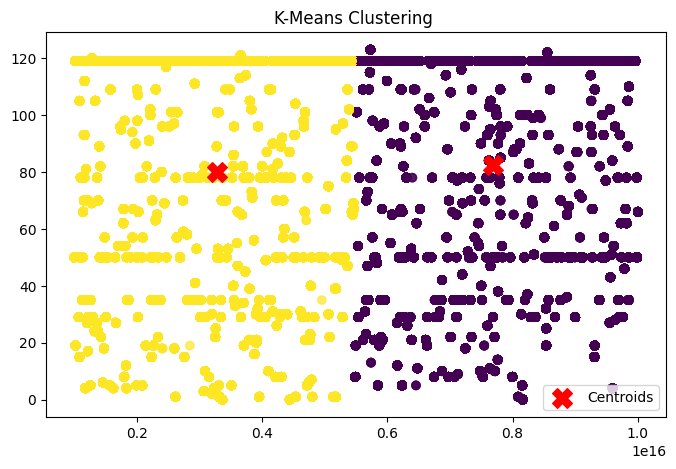

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.model_selection import KFold

# Feature selection
X=df
# Optional: from sklearn.preprocessing import StandardScaler
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)

# Use this if your X is already numeric and clean
X_scaled = X.values  # or use df[...] if not already defined

# --- Gap Statistic Function ---
def gap_statistic(X, n_clusters=2, n_refs=10):
    reference_inertia = []
    for _ in range(n_refs):
        random_data = np.random.uniform(np.min(X, axis=0), np.max(X, axis=0), X.shape)
        km = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
        km.fit(random_data)
        reference_inertia.append(km.inertia_)

    km = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    km.fit(X)
    observed_inertia = km.inertia_

    return np.log(np.mean(reference_inertia)) - np.log(observed_inertia)


# --- Initialize 10-Fold CV ---
kf = KFold(n_splits=10, shuffle=True, random_state=42)

sil_scores = []
ch_scores = []
db_scores = []
wcss_scores = []
gap_scores = []

for fold, (train_idx, _) in enumerate(kf.split(X_scaled), 1):
    X_train = X_scaled[train_idx]

    kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_train)

    sil = silhouette_score(X_train, labels)
    ch = calinski_harabasz_score(X_train, labels)
    db = davies_bouldin_score(X_train, labels)
    wcss = kmeans.inertia_
    gap = gap_statistic(X_train, n_clusters=2)

    sil_scores.append(sil)
    ch_scores.append(ch)
    db_scores.append(db)
    wcss_scores.append(wcss)
    gap_scores.append(gap)

    print(f"Fold {fold}: Silhouette={sil:.4f}, CH={ch:.2f}, DB={db:.4f}, WCSS={wcss:.2f}, Gap={gap:.4f}")

# --- Summary Metrics ---
print("\n--- 10-Fold Average Metrics ---")
print(f"Average Silhouette Score: {np.mean(sil_scores):.4f}")
print(f"Average Calinski-Harabasz Index: {np.mean(ch_scores):.2f}")
print(f"Average Davies-Bouldin Index: {np.mean(db_scores):.4f}")
print(f"Average WCSS: {np.mean(wcss_scores):.2f}")
print(f"Average Gap Statistic: {np.mean(gap_scores):.4f}")

# --- Final Model on Full Data (for Visualization) ---
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
final_labels = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=final_labels, cmap='viridis', alpha=0.7)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            s=200, marker='X', c='red', label="Centroids")
plt.title("K-Means Clustering ")
plt.legend()
plt.show()

## 3. Agglomerative Hierarchical Clustering (AHC), unscaled features

Mini-batch k-means (50 centroids) followed by Ward linkage on the centroids.

Fold 1: Sil=0.5368, CH=462607.50, DB=0.5278, WCSS=627959924618262452824940256165888.00, Gap=-0.0132
Fold 2: Sil=0.5977, CH=638070.66, DB=0.4988, WCSS=584804297570883171042681107251200.00, Gap=-0.0136
Fold 3: Sil=0.5485, CH=465869.79, DB=0.5017, WCSS=633457328968002817888209281744896.00, Gap=-0.0123
Fold 4: Sil=0.6083, CH=695532.50, DB=0.5033, WCSS=628191983823004045961266968133632.00, Gap=-0.0140
Fold 5: Sil=0.5570, CH=523817.23, DB=0.5275, WCSS=610630959738546137135675705655296.00, Gap=-0.0120
Fold 6: Sil=0.5489, CH=466253.82, DB=0.5012, WCSS=575477679051805401103762630639616.00, Gap=-0.0125
Fold 7: Sil=0.6165, CH=746911.34, DB=0.5109, WCSS=600885828925479871870645712191488.00, Gap=-0.0131
Fold 8: Sil=0.5982, CH=640850.08, DB=0.4991, WCSS=612965127649600501708065800716288.00, Gap=-0.0149
Fold 9: Sil=0.5569, CH=523559.20, DB=0.5277, WCSS=628112161234009333862397355491328.00, Gap=-0.0136
Fold 10: Sil=0.5997, CH=648265.00, DB=0.4994, WCSS=587108125510571140345228525830144.00, Gap=-0.0124

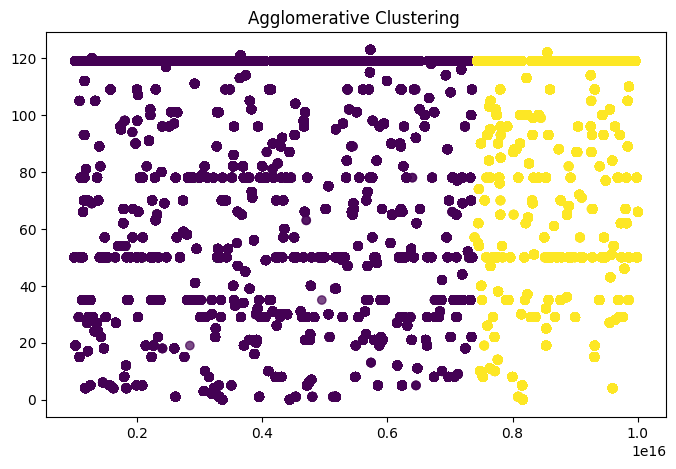

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering, MiniBatchKMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.model_selection import KFold

#X = df[[ 'credit_card','State','City', 'zipcode', 'credit_card_limit',
#         'transaction_dollar_amount', 'Long', 'Lat']]
X=df

# --- Gap Statistic Function ---
def gap_statistic(X, n_clusters=2, n_refs=10):
    reference_inertia = []
    for _ in range(n_refs):
        random_data = np.random.uniform(np.min(X, axis=0), np.max(X, axis=0), X.shape)
        km = MiniBatchKMeans(n_clusters=n_clusters, batch_size=1000, random_state=42)
        km.fit(random_data)
        reference_inertia.append(km.inertia_)

    km = MiniBatchKMeans(n_clusters=n_clusters, batch_size=1000, random_state=42)
    km.fit(X)
    observed_inertia = km.inertia_

    return np.log(np.mean(reference_inertia)) - np.log(observed_inertia)

# --- Prepare Data ---
X_array = np.array(X)  # Ensure it's a NumPy array

# --- Initialize 10-Fold CV ---
kf = KFold(n_splits=10, shuffle=True, random_state=42)

sil_scores = []
ch_scores = []
db_scores = []
wcss_scores = []
gap_scores = []


# --- K-Fold Loop ---
for fold, (train_idx, _) in enumerate(kf.split(X_array), 1):
    X_train = X_array[train_idx]

    # Step 1: MiniBatch KMeans
    mini_kmeans = MiniBatchKMeans(n_clusters=50, batch_size=1000, random_state=42)
    initial_labels = mini_kmeans.fit_predict(X_train)

    # Step 2: Agglomerative Clustering on KMeans Centroids
    agg = AgglomerativeClustering(n_clusters=2, linkage='ward')
    final_labels_on_centroids = agg.fit_predict(mini_kmeans.cluster_centers_)

    # Step 3: Map to full training data
    cluster_map = {i: final_labels_on_centroids[i] for i in range(len(final_labels_on_centroids))}
    predicted_labels = np.array([cluster_map[label] for label in initial_labels])

    # Step 4: Evaluation Metrics
    sil = silhouette_score(X_train, predicted_labels)
    ch = calinski_harabasz_score(X_train, predicted_labels)
    db = davies_bouldin_score(X_train, predicted_labels)
    wcss = mini_kmeans.inertia_
    gap = gap_statistic(X_train, n_clusters=2)

    # Store Scores
    sil_scores.append(sil)
    ch_scores.append(ch)
    db_scores.append(db)
    wcss_scores.append(wcss)
    gap_scores.append(gap)


    print(f"Fold {fold}: Sil={sil:.4f}, CH={ch:.2f}, DB={db:.4f}, WCSS={wcss:.2f}, Gap={gap:.4f}")

# --- Print Averages ---
print("\n--- 10-Fold Average Metrics ---")
print(f"Average Silhouette Score: {np.mean(sil_scores):.4f}")
print(f"Average Calinski-Harabasz Index: {np.mean(ch_scores):.2f}")
print(f"Average Davies-Bouldin Index: {np.mean(db_scores):.4f}")
print(f"Average WCSS: {np.mean(wcss_scores):.2f}")
print(f"Average Gap Statistic: {np.mean(gap_scores):.4f}")


# --- Final Fit & Visualization on Full Data ---
mini_kmeans = MiniBatchKMeans(n_clusters=50, batch_size=1000, random_state=42)
initial_labels = mini_kmeans.fit_predict(X_array)

agg = AgglomerativeClustering(n_clusters=2, linkage='ward')
final_labels_on_centroids = agg.fit_predict(mini_kmeans.cluster_centers_)

cluster_map = {i: final_labels_on_centroids[i] for i in range(len(final_labels_on_centroids))}
predicted_labels = np.array([cluster_map[label] for label in initial_labels])

# Plot (first two features)
plt.figure(figsize=(8, 5))
plt.scatter(X_array[:, 0], X_array[:, 1], c=predicted_labels, cmap='viridis', alpha=0.7)
plt.title("Agglomerative Clustering ")
plt.show()


## 4. Gaussian Mixture Model Clustering (GMMC), standardized features

/tmp/ipython-input-5-4109441547.py:22: RuntimeWarning: invalid value encountered in log
  return np.log(np.mean(reference_log_likelihood)) - np.log(observed_log_likelihood)


Fold 1: Sil=0.2477, CH=66336.83, DB=1.5719, WCSS≈12.63, Gap=nan


/tmp/ipython-input-5-4109441547.py:22: RuntimeWarning: invalid value encountered in log
  return np.log(np.mean(reference_log_likelihood)) - np.log(observed_log_likelihood)


Fold 2: Sil=0.2477, CH=66571.60, DB=1.5699, WCSS≈12.58, Gap=nan


/tmp/ipython-input-5-4109441547.py:22: RuntimeWarning: invalid value encountered in log
  return np.log(np.mean(reference_log_likelihood)) - np.log(observed_log_likelihood)


Fold 3: Sil=0.2475, CH=66395.70, DB=1.5715, WCSS≈12.59, Gap=nan


... (11 outputs left out)

Fold 9: Sil=0.5578, CH=29507.07, DB=0.7287, WCSS≈14.65, Gap=nan


/tmp/ipython-input-5-4109441547.py:22: RuntimeWarning: invalid value encountered in log
  return np.log(np.mean(reference_log_likelihood)) - np.log(observed_log_likelihood)


Fold 10: Sil=0.2479, CH=66765.92, DB=1.5686, WCSS≈12.54, Gap=nan

--- 10-Fold Average Metrics ---
Average Silhouette Score: 0.2787
Average Calinski-Harabasz Index: 62838.53
Average Davies-Bouldin Index: 1.4862
Average WCSS: 12.79
Average Gap Statistic: nan

--- Final GMM Model on Full Data ---
Silhouette Score: 0.2477
Calinski-Harabasz Index: 73964.0476
Davies-Bouldin Index: 1.5701
BIC (Bayesian Information Criterion): 1355964.6523 (Lower is better)
AIC (Akaike Information Criterion): 1355021.8457 (Lower is better)


/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


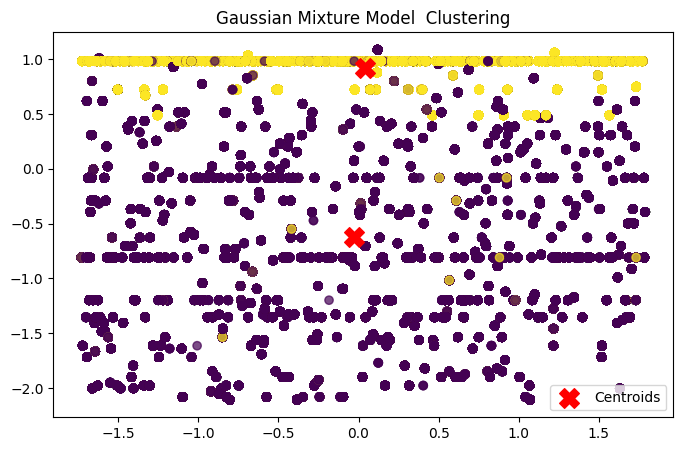

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

# --- Gap Statistic for GMM ---
def gap_statistic(X, n_clusters=2, n_refs=10):
    reference_log_likelihood = []
    for _ in range(n_refs):
        random_data = np.random.uniform(np.min(X, axis=0), np.max(X, axis=0), X.shape)
        gmm = GaussianMixture(n_components=n_clusters, random_state=42)
        gmm.fit(random_data)
        reference_log_likelihood.append(gmm.score(random_data))

    gmm = GaussianMixture(n_components=n_clusters, random_state=42)
    gmm.fit(X)
    observed_log_likelihood = gmm.score(X)

    return np.log(np.mean(reference_log_likelihood)) - np.log(observed_log_likelihood)

# --- Load and scale the data ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- K-Fold Initialization ---
kf = KFold(n_splits=10, shuffle=True, random_state=42)

sil_scores = []
ch_scores = []
db_scores = []
wcss_scores = []
gap_scores = []

# --- K-Fold Loop ---
for fold, (train_idx, _) in enumerate(kf.split(X_scaled), 1):
    X_train = X_scaled[train_idx]

    gmm = GaussianMixture(n_components=2, random_state=42)
    predicted_labels = gmm.fit_predict(X_train)

    sil = silhouette_score(X_train, predicted_labels)
    ch = calinski_harabasz_score(X_train, predicted_labels)
    db = davies_bouldin_score(X_train, predicted_labels)
    gap = gap_statistic(X_train, n_clusters=2)

    # Approximate WCSS as trace of covariance
    wcss = np.sum([np.trace(cov) for cov in gmm.covariances_])

    sil_scores.append(sil)
    ch_scores.append(ch)
    db_scores.append(db)
    wcss_scores.append(wcss)
    gap_scores.append(gap)

    print(f"Fold {fold}: Sil={sil:.4f}, CH={ch:.2f}, DB={db:.4f}, WCSS≈{wcss:.2f}, Gap={gap:.4f}")

# --- Print Averages ---
print("\n--- 10-Fold Average Metrics ---")
print(f"Average Silhouette Score: {np.mean(sil_scores):.4f}")
print(f"Average Calinski-Harabasz Index: {np.mean(ch_scores):.2f}")
print(f"Average Davies-Bouldin Index: {np.mean(db_scores):.4f}")
print(f"Average WCSS: {np.mean(wcss_scores):.2f}")
print(f"Average Gap Statistic: {np.mean(gap_scores):.4f}")

# --- Final GMM Fit on Full Data ---
gmm = GaussianMixture(n_components=2, random_state=42)
predicted_labels = gmm.fit_predict(X_scaled)

silhouette = silhouette_score(X_scaled, predicted_labels)
calinski_harabasz = calinski_harabasz_score(X_scaled, predicted_labels)
davies_bouldin = davies_bouldin_score(X_scaled, predicted_labels)
bic = gmm.bic(X_scaled)
aic = gmm.aic(X_scaled)

print("\n--- Final GMM Model on Full Data ---")
print(f"Silhouette Score: {silhouette:.4f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz:.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")
print(f"BIC (Bayesian Information Criterion): {bic:.4f} (Lower is better)")
print(f"AIC (Akaike Information Criterion): {aic:.4f} (Lower is better)")

# --- Final Visualization ---
plt.figure(figsize=(8, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=predicted_labels, cmap='viridis', alpha=0.7)
plt.scatter(gmm.means_[:, 0], gmm.means_[:, 1], s=200, marker='X', c='red', label="Centroids")
plt.title("Gaussian Mixture Model  Clustering")
plt.legend()
plt.show()


## 5. Fuzzy C-Means Clustering (FCMC), unscaled features

In [7]:
pip install fuzzy-c-means

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 53.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 4.7 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.16.0
    Uninstalling typer-0.16.0:
      Successfully uninstalled typer-0.16.0
  Attempting uninstall: tabulate
    Found existing installation: tabulate 0.9.0
    Uninstalling tabulate-0.9.0:
      Successfully uninstalled tabulate-0.9.0
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.11.0 requires tabulate>=0.9, but you have tabulate 0.8.10 which is incompatible.
gradio 5.37.0 requires typer<1.0,>=0

Fold 1: Sil=0.6168, CH=748114.92, DB=0.5111, WCSS=299609280012709134336.00, Gap=34.9384
Fold 2: Sil=0.6168, CH=748060.33, DB=0.5111, WCSS=299513000439943397376.00, Gap=34.9379
Fold 3: Sil=0.6170, CH=749078.98, DB=0.5107, WCSS=299448161796612227072.00, Gap=34.9395
Fold 4: Sil=0.6167, CH=747732.46, DB=0.5113, WCSS=299659258658192949248.00, Gap=34.9384
Fold 5: Sil=0.6169, CH=748690.72, DB=0.5110, WCSS=299459925863366787072.00, Gap=34.9403
Fold 6: Sil=0.6171, CH=749165.28, DB=0.5107, WCSS=299496326253192937472.00, Gap=34.9391
Fold 7: Sil=0.6167, CH=747663.78, DB=0.5114, WCSS=299547216066794291200.00, Gap=34.9384
Fold 8: Sil=0.6165, CH=747235.64, DB=0.5115, WCSS=299656426313120415744.00, Gap=34.9382
Fold 9: Sil=0.6168, CH=748175.19, DB=0.5111, WCSS=299533613145809027072.00, Gap=34.9397
Fold 10: Sil=0.6167, CH=747854.91, DB=0.5112, WCSS=299496843373583138816.00, Gap=34.9399

--- 10-Fold Average Metrics ---
Average Silhouette Score: 0.6168
Average Calinski-Harabasz Index: 748177.22
Average Da

/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


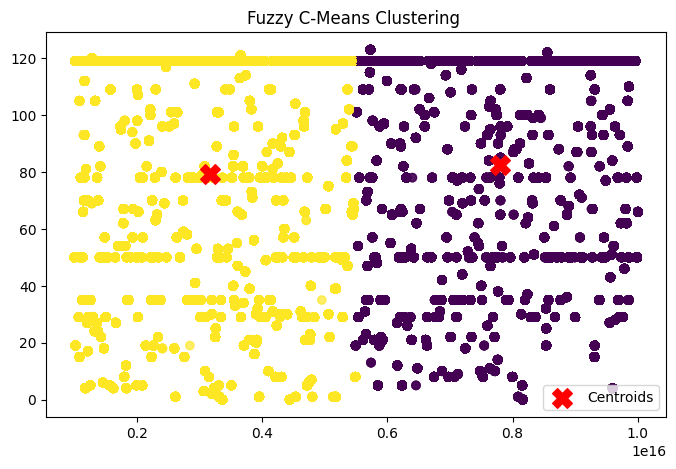

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fcmeans import FCM
from sklearn.model_selection import KFold
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans

# --- Gap Statistic Function ---
def gap_statistic(X, n_clusters=2, n_refs=10):
    reference_inertia = []
    for _ in range(n_refs):
        random_data = np.random.uniform(np.min(X, axis=0), np.max(X, axis=0), X.shape)
        km = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
        km.fit(random_data)
        reference_inertia.append(km.inertia_)

    fcm = FCM(n_clusters=n_clusters)
    fcm.fit(X)
    observed_inertia = np.sum(np.min(cdist(X, fcm.centers), axis=1))  # WCSS-like approximation

    return np.log(np.mean(reference_inertia)) - np.log(observed_inertia)

# --- Prepare and Scale Data ---
scaler = StandardScaler()
#X_scaled = scaler.fit_transform(X)  # Ensure scaled input
X_scaled = np.array(X)
#X_scaled = X
# --- K-Fold Initialization ---
kf = KFold(n_splits=10, shuffle=True, random_state=42)

sil_scores = []
ch_scores = []
db_scores = []
wcss_scores = []
gap_scores = []

# --- 10-Fold Evaluation ---
for fold, (train_idx, _) in enumerate(kf.split(X_scaled), 1):
    X_train = X_scaled[train_idx]

    fcm = FCM(n_clusters=2, m=2.0, max_iter=150, random_state=42)
    fcm.fit(X_train)

    membership = fcm.u
    labels = np.argmax(membership, axis=1)

    sil = silhouette_score(X_train, labels)
    ch = calinski_harabasz_score(X_train, labels)
    db = davies_bouldin_score(X_train, labels)
    wcss = np.sum(np.min(cdist(X_train, fcm.centers), axis=1))
    gap = gap_statistic(X_train, n_clusters=2)

    sil_scores.append(sil)
    ch_scores.append(ch)
    db_scores.append(db)
    wcss_scores.append(wcss)
    gap_scores.append(gap)

    print(f"Fold {fold}: Sil={sil:.4f}, CH={ch:.2f}, DB={db:.4f}, WCSS={wcss:.2f}, Gap={gap:.4f}")

# --- Summary Metrics ---
print("\n--- 10-Fold Average Metrics ---")
print(f"Average Silhouette Score: {np.mean(sil_scores):.4f}")
print(f"Average Calinski-Harabasz Index: {np.mean(ch_scores):.2f}")
print(f"Average Davies-Bouldin Index: {np.mean(db_scores):.4f}")
print(f"Average WCSS: {np.mean(wcss_scores):.2f}")
print(f"Average Gap Statistic: {np.mean(gap_scores):.4f}")

# --- Final Fit on Full Data for Visualization ---
fcm = FCM(n_clusters=2, m=2.0, max_iter=150, random_state=42)
fcm.fit(X_scaled)

membership = fcm.u
labels = np.argmax(membership, axis=1)

# --- Plot ---
plt.figure(figsize=(8, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap='viridis', alpha=0.7)
plt.scatter(fcm.centers[:, 0], fcm.centers[:, 1], s=200, marker='X', c='red', label="Centroids")
plt.title("Fuzzy C-Means Clustering ")
plt.legend()
plt.show()
